<a href="https://colab.research.google.com/github/aviksarkar0204-stack/AI_LAB_ASSIGNMENTS/blob/main/Assigment4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## A* Algorithm

In [16]:
import heapq
import networkx as nx
import matplotlib.pyplot as plt

In [17]:
#Define the graph with edge cost
graph = {
    "A" : [("B", 1), ("C", 4)],
    "B" : [("D",2),  ("E",5)],
    "C" : [('F', 1)],
    "D" : [],
    "E" : [('G', 2)],
    "F" : [('G', 3)],
    "G" : []
}

In [18]:
heuristic = {
    "A" : 7,
    "B" : 6,
    "C" : 2,
    "D" : 5,
    "E" : 2,
    "F" : 1,
    "G" : 0
}

In [19]:
def astar(graph,heuristic, start, goal):
  pq = [(heuristic[start],0,start, [start])]
  visited = set()
  while pq:
    f,g,node,path = heapq.heappop(pq)
    if node == goal:
      return path, g # Modified: return path and its cost (g)
    if node in visited:
      continue
    visited.add(node)
    for neighbor,cost in graph[node]:
      new_g = g + cost
      new_f = new_g + heuristic[neighbor]
      heapq.heappush(pq, (new_f, new_g, neighbor, path + [neighbor]))
  return None, float("inf")

In [20]:
path,cost = astar(graph,heuristic, "A", "G")
print("shortest path:")
print('->'.join(path))
print("Total cost:",cost)

shortest path:
A->B->E->G
Total cost: 8


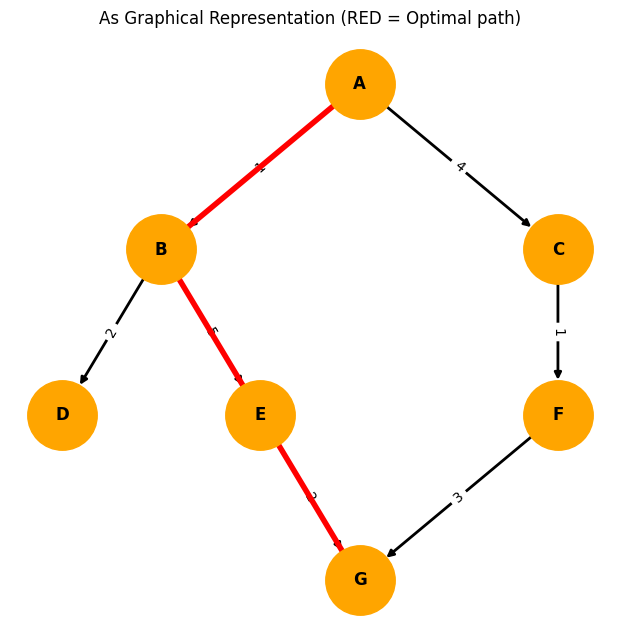

In [22]:
G = nx.DiGraph()

for node in graph:
  for neighbor, weight in graph[node]:
    G.add_edge(node, neighbor, weight=weight)

pos = {
    'A':(0,3),
    'B':(-1,2),
    'C':(1,2),
    'D':(-1.5,1),
    'E':(-0.5,1),
    'F':(1,1),
    'G':(0,0)
}
plt.figure(figsize=(6,6))
nx.draw(G,pos,with_labels = True,
        node_color = 'orange',
        node_size = 2500,
        font_weight = 'bold',
        edge_color = 'black',
        arrows = True,
        width = 2)
edge_labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=edge_labels)

path_edge = list(zip(path[:-1],path[1:]))
nx.draw_networkx_edges(G,pos,edgelist=path_edge,edge_color='red',width=4,arrows = True)
plt.title("As Graphical Representation (RED = Optimal path)")
plt.axis('off')
plt.show()


## AO* Graph

In [23]:
import networkx as nx
import matplotlib.pyplot as plt

In [24]:
graph = {
    'A':{'type':"OR",'children':[('B',1),('C',1)]},
    'B':{'type':"AND",'children':[('D',1),('E',1)]},
    'C':{'type':"OR",'children':[('F',1),('G',1)]},
    'D':{'type':"LEAF",'cost':2},
    'E':{'type':"LEAF",'cost':3},
    'F':{'type':"LEAF",'cost':4},
    'G':{'type':"LEAF",'cost':6}
}

Optimal Solution path:
A->C->F
Total cost: 6


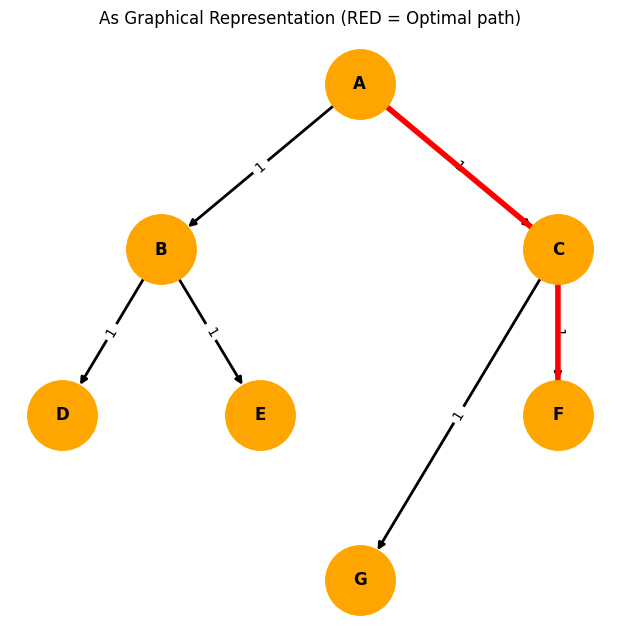

In [27]:
def ao_star(node):
  info = graph[node]
  if info['type'] == 'LEAF':
    return info['cost'],[node]
  if info['type'] == 'OR':
    min_cost = float('inf')
    min_path = []
    for child,cost in info['children']:
      child_cost,child_path = ao_star(child)
      total_cost = cost + child_cost
      if total_cost < min_cost:
        min_cost = total_cost
        min_path = [node] + child_path
    return min_cost,min_path

  if info['type'] == 'AND':
    total_cost = 0 # Initialize total_cost for AND node to 0
    full_path = [node]
    for child,cost in info['children']:
      child_cost,child_path = ao_star(child)
      total_cost += cost + child_cost # Use 'cost' from the loop, not 'edge_cost'
      full_path += child_path
    return total_cost, full_path # Fix typo: 'full' should be 'full_path'

cost, path = ao_star('A')
print("Optimal Solution path:")
print("->".join(path))
print("Total cost:",cost)

G = nx.DiGraph()
for node,info in graph.items():
  if 'children' in info:
    for child,weight in info['children']:
      G.add_edge(node,child,weight=weight)
pos = {
    'A':(0,3),
    'B':(-1,2),
    'C':(1,2),
    'D':(-1.5,1),
    'E':(-0.5,1),
    'F':(1,1),
    'G':(0,0)
}
plt.figure(figsize=(6,6))
nx.draw(G,pos,with_labels = True,
        node_color = 'orange',
        node_size = 2500,
        font_weight = 'bold',
        edge_color = 'black',
        arrows = True,
        width = 2)
edge_labels = nx.get_edge_attributes(G,'weight')
nx.draw_networkx_edge_labels(G,pos,edge_labels=edge_labels)

path_edge = list(zip(path[:-1],path[1:]))
nx.draw_networkx_edges(G,pos,edgelist=path_edge,edge_color='red',width=4,arrows = True)
plt.title("As Graphical Representation (RED = Optimal path)")
plt.axis('off')
plt.show()